# Expérimentation complémentaire — Impact du scaling

## Objectif

Lors de la phase de prétraitement, la standardisation des variables numériques avait été identifiée comme une transformation pouvant être appliquée lors de la modélisation pour les algorithmes sensibles à l'échelle des variables.

L'objectif de cette expérimentation complémentaire est d'évaluer l'impact d'une standardisation des variables sur les performances de plusieurs modèles :

- Régression linéaire ;
- Ridge ;
- Lasso ;
- Perceptron Multicouche (MLP).

Les modèles fondés sur les arbres, tels que l'Arbre de décision, Random Forest, XGBoost et LightGBM, ne sont pas concernés par cette expérimentation car leur fonctionnement est peu sensible à l'échelle des variables.

Afin d'isoler l'effet du scaling, les mêmes jeux d'entraînement et de test ainsi que les mêmes configurations de modèles seront conservés autant que possible.

La standardisation sera ajustée uniquement sur le jeu d'entraînement afin d'éviter toute fuite d'information vers le jeu de test.

## 1. Préparation des données

Afin de comparer correctement les performances obtenues avec et sans standardisation, cette expérimentation reprend exactement les mêmes jeux d'entraînement et de test que la modélisation principale.

Les jeux de données déjà préparés lors de la phase de prétraitement sont directement réutilisés. Ils correspondent à une séparation de 80 % des observations pour l'entraînement et 20 % pour le test, réalisée avec `random_state=42`.

Cette approche permet de conserver exactement les mêmes observations et les mêmes variables que dans la modélisation principale. Les mêmes jeux d'entraînement et de test sont conservés afin d'évaluer l'effet de la standardisation. Pour le MLP, une comparaison contrôlée est réalisée en utilisant un découpage apprentissage/validation commun, des poids initiaux identiques et les mêmes paramètres d'entraînement.

Afin d'éviter toute fuite d'information, le scaler sera ajusté uniquement sur le jeu d'entraînement puis appliqué au jeu de test.

In [14]:
# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

In [15]:
# ============================================================
# CHARGEMENT DES JEUX DE DONNÉES
# ============================================================

X_train = pd.read_csv("../data/X_train_final.csv")
X_test = pd.read_csv("../data/X_test_final.csv")

y_train = pd.read_csv("../data/y_train.csv")["co2"]
y_test = pd.read_csv("../data/y_test.csv")["co2"]

In [16]:
# Vérification des dimensions

print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test  :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test  :", y_test.shape)

Dimensions de X_train : (44002, 93)
Dimensions de X_test  : (11001, 93)
Dimensions de y_train : (44002,)
Dimensions de y_test  : (11001,)


## 2. Standardisation des variables

La standardisation consiste à transformer les variables afin qu'elles soient exprimées sur une échelle comparable, avec une moyenne proche de 0 et un écart-type proche de 1.

Le `StandardScaler` est ajusté uniquement sur le jeu d'entraînement (`X_train`). Les paramètres appris sur ce jeu sont ensuite utilisés pour transformer `X_train` et `X_test`.

Cette méthode permet d'éviter toute fuite d'information du jeu de test vers le jeu d'entraînement.

In [17]:
# ============================================================
# STANDARDISATION DES VARIABLES
# ============================================================

# Création du scaler
scaler = StandardScaler()

# Apprentissage uniquement sur X_train
X_train_scaled = scaler.fit_transform(X_train)

# Application au jeu de test avec les paramètres appris sur X_train
X_test_scaled = scaler.transform(X_test)

In [18]:
# Vérification des dimensions après standardisation

print("Dimensions de X_train_scaled :", X_train_scaled.shape)
print("Dimensions de X_test_scaled  :", X_test_scaled.shape)

# Vérification de la standardisation sur X_train
print("\nMoyenne globale de X_train_scaled :", X_train_scaled.mean())
print("Écart-type global de X_train_scaled :", X_train_scaled.std())

Dimensions de X_train_scaled : (44002, 93)
Dimensions de X_test_scaled  : (11001, 93)

Moyenne globale de X_train_scaled : 5.736868262956207e-18
Écart-type global de X_train_scaled : 0.9999999999999998


## 3. Régression linéaire avec standardisation

La régression linéaire est réentraînée sur les variables standardisées afin de mesurer l'impact du scaling sur ses performances.

Les résultats obtenus seront comparés à ceux de la modélisation principale réalisée sans standardisation.

In [19]:
# ============================================================
# RÉGRESSION LINÉAIRE AVEC STANDARDISATION
# ============================================================

linear_scaled = LinearRegression()

# Entraînement
linear_scaled.fit(X_train_scaled, y_train)

# Prédictions
y_pred_linear_scaled = linear_scaled.predict(X_test_scaled)

# Métriques
mae_linear_scaled = mean_absolute_error(y_test, y_pred_linear_scaled)
rmse_linear_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_linear_scaled)
)
r2_linear_scaled = r2_score(y_test, y_pred_linear_scaled)
mape_linear_scaled = mean_absolute_percentage_error(
    y_test,
    y_pred_linear_scaled
)

print(f"MAE  : {mae_linear_scaled:.4f}")
print(f"RMSE : {rmse_linear_scaled:.4f}")
print(f"R²   : {r2_linear_scaled:.4f}")
print(f"MAPE : {mape_linear_scaled:.4f}")

MAE  : 1.0922
RMSE : 1.7402
R²   : 0.9974
MAPE : 0.0059


### Interprétation

La standardisation n'a pas modifié les performances de la régression linéaire. Les quatre métriques obtenues sont identiques à celles du modèle entraîné sans scaling.

Ce résultat montre que, dans cette expérimentation, le changement d'échelle des variables n'apporte pas de gain prédictif à la régression linéaire. La standardisation modifie l'échelle des coefficients du modèle, mais pas sa capacité prédictive.

## 4. Régression Ridge avec standardisation

La régression Ridge ajoute une pénalisation L2 à la régression linéaire afin de limiter l'amplitude des coefficients.

Contrairement à la régression linéaire classique, la régularisation est sensible à l'échelle des variables. La standardisation permet donc d'appliquer la pénalisation de manière plus homogène entre les différentes variables.

Dans un premier temps, le modèle est entraîné avec `alpha=1`, correspondant à la configuration initiale utilisée dans la modélisation principale, afin d'isoler l'effet du scaling.

In [20]:
# ============================================================
# RIDGE AVEC STANDARDISATION
# ============================================================

ridge_scaled = Ridge(alpha=1.0)

# Entraînement
ridge_scaled.fit(X_train_scaled, y_train)

# Prédictions
y_pred_ridge_scaled = ridge_scaled.predict(X_test_scaled)

# Métriques
mae_ridge_scaled = mean_absolute_error(
    y_test,
    y_pred_ridge_scaled
)

rmse_ridge_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge_scaled)
)

r2_ridge_scaled = r2_score(
    y_test,
    y_pred_ridge_scaled
)

mape_ridge_scaled = mean_absolute_percentage_error(
    y_test,
    y_pred_ridge_scaled
)

print(f"MAE  : {mae_ridge_scaled:.4f}")
print(f"RMSE : {rmse_ridge_scaled:.4f}")
print(f"R²   : {r2_ridge_scaled:.4f}")
print(f"MAPE : {mape_ridge_scaled:.4f}")

MAE  : 1.0925
RMSE : 1.7401
R²   : 0.9974
MAPE : 0.0060


### Interprétation

La régression Ridge avec standardisation (`alpha=1`) obtient de très bonnes performances prédictives, avec une MAE de **1,0925 g/km**, une RMSE de **1,7401 g/km** et un coefficient de détermination R² de **0,9974**. La MAPE atteint **0,0060**, soit environ **0,60 %**.

Ces résultats montrent que le modèle explique une très grande partie de la variabilité des émissions de CO₂ et présente des erreurs de prédiction relativement faibles.

La standardisation est particulièrement pertinente pour Ridge, car la régularisation L2 dépend de l'échelle des variables explicatives.

Toutefois, pour déterminer si elle apporte un gain de performance, il est nécessaire de comparer ces résultats à ceux du modèle Ridge sans standardisation, évalué sur les mêmes données.

### Optimisation de Ridge après standardisation

La valeur optimale du paramètre `alpha` peut dépendre de l'échelle des variables.

Un `GridSearchCV` est donc réalisé sur les données standardisées en utilisant la même grille de valeurs que dans la modélisation principale. Cette démarche permet de déterminer si la standardisation modifie le niveau de régularisation optimal du modèle.

In [21]:
# ============================================================
# GRIDSEARCHCV - RIDGE AVEC STANDARDISATION
# ============================================================

# Pipeline : standardisation puis régression Ridge
pipeline_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Même grille de valeurs que dans le notebook initial
param_grid_ridge = {
    "ridge__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid_ridge_scaled = GridSearchCV(
    estimator=pipeline_ridge,
    param_grid=param_grid_ridge,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Le pipeline effectue la standardisation dans chaque pli
grid_ridge_scaled.fit(X_train, y_train)

print("Meilleur alpha :", grid_ridge_scaled.best_params_["ridge__alpha"])
print(f"Meilleur score R² CV : {grid_ridge_scaled.best_score_:.4f}")

Meilleur alpha : 1
Meilleur score R² CV : 0.9971


In [22]:
# Meilleur modèle obtenu par GridSearchCV
best_ridge_scaled = grid_ridge_scaled.best_estimator_

# Prédictions sur le jeu de test
# Le Pipeline applique automatiquement la standardisation
y_pred_best_ridge_scaled = best_ridge_scaled.predict(X_test)

# Métriques
mae_best_ridge_scaled = mean_absolute_error(
    y_test, y_pred_best_ridge_scaled
)

rmse_best_ridge_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_best_ridge_scaled)
)

r2_best_ridge_scaled = r2_score(
    y_test, y_pred_best_ridge_scaled
)

mape_best_ridge_scaled = mean_absolute_percentage_error(
    y_test, y_pred_best_ridge_scaled
)

# Affichage des performances
print(f"MAE  : {mae_best_ridge_scaled:.4f}")
print(f"RMSE : {rmse_best_ridge_scaled:.4f}")
print(f"R²   : {r2_best_ridge_scaled:.4f}")
print(f"MAPE : {mape_best_ridge_scaled:.4f}")

MAE  : 1.0925
RMSE : 1.7401
R²   : 0.9974
MAPE : 0.0060


### Interprétation de l'optimisation

Après standardisation, le `GridSearchCV` sélectionne `alpha=1`, avec un R² moyen en validation croisée de **0,9971**.

Dans la modélisation principale sans standardisation, l'optimisation avait retenu `alpha=0.0001`. Cette différence montre que la mise à l'échelle des variables influence le niveau de régularisation sélectionné par Ridge.

Le modèle optimisé obtient une **MAE de 1,0925 g/km**, une **RMSE de 1,7401 g/km**, un **R² de 0,9974** et une **MAPE de 0,0060**, soit environ **0,60 %**.

Ces performances sont identiques à celles du modèle Ridge standardisé avec `alpha=1`, ce qui est cohérent puisque le `GridSearchCV` a retenu cette même valeur.

La standardisation permet ainsi d'appliquer la régularisation L2 sur des variables placées sur une échelle comparable. Toutefois, les performances étant déjà très élevées, son intérêt doit être apprécié en comparant les résultats aux modèles sans standardisation sur les mêmes données actualisées.

## 5. Régression Lasso avec standardisation

La régression Lasso applique une pénalisation L1 pouvant conduire certains coefficients à devenir nuls et ainsi réaliser une sélection implicite de variables.

Cette pénalisation étant sensible à l'échelle des variables, le modèle est réentraîné après standardisation.

Dans un premier temps, `alpha=1` est conservé afin de comparer directement les résultats avec ceux du modèle Lasso initial de la modélisation principale.

In [23]:
# ============================================================
# LASSO AVEC STANDARDISATION
# ============================================================

lasso_scaled = Lasso(alpha=1.0)

# Entraînement
lasso_scaled.fit(X_train_scaled, y_train)

# Prédictions
y_pred_lasso_scaled = lasso_scaled.predict(X_test_scaled)

# Métriques
mae_lasso_scaled = mean_absolute_error(
    y_test, y_pred_lasso_scaled
)

rmse_lasso_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso_scaled)
)

r2_lasso_scaled = r2_score(
    y_test, y_pred_lasso_scaled
)

mape_lasso_scaled = mean_absolute_percentage_error(
    y_test, y_pred_lasso_scaled
)

print(f"MAE  : {mae_lasso_scaled:.4f}")
print(f"RMSE : {rmse_lasso_scaled:.4f}")
print(f"R²   : {r2_lasso_scaled:.4f}")
print(f"MAPE : {mape_lasso_scaled:.4f}")

MAE  : 1.9067
RMSE : 3.0057
R²   : 0.9923
MAPE : 0.0102


### Interprétation

La régression Lasso avec standardisation (`alpha=1`) obtient une MAE de **1,9067 g/km** et une RMSE de **3,0057 g/km**. Le R² atteint **0,9923**, tandis que la MAPE est de **0,0102**, soit environ **1,02 %**.

Ces résultats montrent que le modèle conserve une très bonne capacité prédictive après standardisation.

La mise à l'échelle des variables est particulièrement importante pour Lasso, car la pénalisation L1 agit directement sur les coefficients et peut être fortement influencée lorsque les variables sont exprimées sur des échelles différentes.

Malgré ces bonnes performances, Lasso reste moins performant que la régression linéaire et Ridge avec standardisation, qui obtiennent tous deux un R² de **0,9974** et des erreurs de prédiction plus faibles.

L'effet précis de la standardisation sur Lasso sera confirmé par la comparaison avec les résultats du modèle sans scaling sur les mêmes données actualisées.

### Optimisation de Lasso après standardisation

In [24]:
# ============================================================
# GRIDSEARCHCV - LASSO AVEC STANDARDISATION
# ============================================================

# Pipeline : standardisation puis régression Lasso
pipeline_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=10000))
])

# Grille des hyperparamètres
param_grid_lasso = {
    "lasso__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid_lasso_scaled = GridSearchCV(
    estimator=pipeline_lasso,
    param_grid=param_grid_lasso,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Entraînement sur les données non standardisées
# Le Pipeline réalise la standardisation dans chaque pli
grid_lasso_scaled.fit(X_train, y_train)

print("Meilleur alpha :", grid_lasso_scaled.best_params_["lasso__alpha"])
print(f"Meilleur score R² CV : {grid_lasso_scaled.best_score_:.4f}")

Meilleur alpha : 0.0001
Meilleur score R² CV : 0.9971


In [25]:
# Meilleur modèle Lasso
best_lasso_scaled = grid_lasso_scaled.best_estimator_

# Prédictions
# Le Pipeline applique automatiquement la standardisation
y_pred_best_lasso_scaled = best_lasso_scaled.predict(X_test)

# Métriques
mae_best_lasso_scaled = mean_absolute_error(
    y_test, y_pred_best_lasso_scaled
)

rmse_best_lasso_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_best_lasso_scaled)
)

r2_best_lasso_scaled = r2_score(
    y_test, y_pred_best_lasso_scaled
)

mape_best_lasso_scaled = mean_absolute_percentage_error(
    y_test, y_pred_best_lasso_scaled
)

print(f"MAE  : {mae_best_lasso_scaled:.4f}")
print(f"RMSE : {rmse_best_lasso_scaled:.4f}")
print(f"R²   : {r2_best_lasso_scaled:.4f}")
print(f"MAPE : {mape_best_lasso_scaled:.4f}")

MAE  : 1.0922
RMSE : 1.7401
R²   : 0.9974
MAPE : 0.0059


### Interprétation de l'optimisation

Après standardisation, le `GridSearchCV` sélectionne `alpha=0.0001`, avec un R² moyen en validation croisée de **0,9971**.

Le Lasso optimisé obtient une **MAE de 1,0922 g/km**, une **RMSE de 1,7401 g/km**, un **R² de 0,9974** et une **MAPE de 0,0059**, soit environ **0,59 %**.

Ces performances sont nettement meilleures que celles du Lasso standardisé avec `alpha=1`, qui obtenait une MAE de 1,9067 g/km et un R² de 0,9923.

La diminution du paramètre `alpha` réduit fortement la pénalisation L1, permettant au modèle de conserver davantage d'informations pour effectuer ses prédictions.

Après optimisation, les performances de Lasso deviennent pratiquement identiques à celles de la régression linéaire classique.

La standardisation permet d'appliquer la régularisation sur des variables placées sur une échelle comparable. Toutefois, le gain observé ici provient principalement de l'optimisation du paramètre `alpha`. Une comparaison avec le Lasso optimisé sans standardisation reste nécessaire pour isoler l'effet du scaling.

## 6. Comparaison des MLP avec et sans standardisation

Les réseaux de neurones sont particulièrement sensibles à l'échelle des variables d'entrée. Des variables présentant des ordres de grandeur très différents peuvent rendre l'optimisation plus difficile et ralentir la convergence du modèle.

Afin d'évaluer l'impact de la standardisation, deux réseaux de neurones MLP sont entraînés et évalués selon un protocole identique :

- **MLP sans standardisation** : utilisation des variables explicatives dans leur échelle d'origine.
- **MLP avec standardisation** : utilisation des variables transformées à l'aide de `StandardScaler`.

Les deux modèles utilisent la même architecture (64 et 32 neurones cachés), les mêmes poids initiaux, les mêmes données d'apprentissage, de validation et de test, ainsi que les mêmes paramètres d'entraînement : optimiseur Adam, fonction de perte MSE, 100 epochs et batch size de 32.

Une graine aléatoire (`seed=42`) est fixée pour améliorer la reproductibilité. L'ordre des observations est également maintenu identique pendant les deux entraînements (`shuffle=False`).

La standardisation est ajustée uniquement sur le sous-ensemble d'apprentissage, puis appliquée aux ensembles de validation et de test afin d'éviter toute fuite d'information.

**L'objectif est d'isoler l'effet de la standardisation sur la convergence et les performances prédictives du MLP.**

In [7]:
# ============================================================
# PRÉPARATION DES DONNÉES POUR LA COMPARAISON CONTRÔLÉE
# ============================================================

# Keras validation_split=0.2 utilise les 20 % de fin
# des données avant le mélange effectué à l'entraînement.
n_train = int(len(X_train) * 0.8)

# Même découpage pour les deux MLP
X_mlp_train = X_train.iloc[:n_train]
X_mlp_val = X_train.iloc[n_train:]

y_mlp_train = y_train.iloc[:n_train]
y_mlp_val = y_train.iloc[n_train:]

# Standardisation ajustée uniquement sur l'apprentissage
scaler_mlp = StandardScaler()

X_mlp_train_scaled = scaler_mlp.fit_transform(X_mlp_train)
X_mlp_val_scaled = scaler_mlp.transform(X_mlp_val)
X_mlp_test_scaled = scaler_mlp.transform(X_test)

# Vérification
print("Apprentissage :", X_mlp_train.shape)
print("Validation    :", X_mlp_val.shape)
print("Test          :", X_test.shape)

Apprentissage : (35201, 93)
Validation    : (8801, 93)
Test          : (11001, 93)


In [8]:

# Reproductibilité
tf.keras.utils.set_random_seed(42)

# Fonction de construction du MLP
def construire_mlp():
    model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1)
    ])

    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )

    return model


# MLP sans standardisation
mlp_sans_scaling = construire_mlp()

# MLP avec standardisation
mlp_avec_scaling = construire_mlp()

# Copie des mêmes poids initiaux
mlp_avec_scaling.set_weights(mlp_sans_scaling.get_weights())

# Vérification
print("MLP sans scaling :", mlp_sans_scaling.count_params(), "paramètres")
print("MLP avec scaling :", mlp_avec_scaling.count_params(), "paramètres")

poids_identiques = all(
    (w1 == w2).all()
    for w1, w2 in zip(
        mlp_sans_scaling.get_weights(),
        mlp_avec_scaling.get_weights()
    )
)

print("Poids initiaux identiques :", poids_identiques)

MLP sans scaling : 8129 paramètres
MLP avec scaling : 8129 paramètres
Poids initiaux identiques : True


In [9]:
# ============================================================
# ENTRAÎNEMENT COMPARATIF DES DEUX MLP
# ============================================================

# 1. MLP SANS STANDARDISATION
print("=" * 60)
print("ENTRAÎNEMENT DU MLP SANS STANDARDISATION")
print("=" * 60)

history_mlp_sans_scaling = mlp_sans_scaling.fit(
    X_mlp_train,
    y_mlp_train,
    validation_data=(X_mlp_val, y_mlp_val),
    epochs=100,
    batch_size=32,
    shuffle=False,
    verbose=1
)

# 2. MLP AVEC STANDARDISATION
print("\n" + "=" * 60)
print("ENTRAÎNEMENT DU MLP AVEC STANDARDISATION")
print("=" * 60)

history_mlp_avec_scaling = mlp_avec_scaling.fit(
    X_mlp_train_scaled,
    y_mlp_train,
    validation_data=(X_mlp_val_scaled, y_mlp_val),
    epochs=100,
    batch_size=32,
    shuffle=False,
    verbose=1
)

print("\nEntraînement des deux MLP terminé.")

ENTRAÎNEMENT DU MLP SANS STANDARDISATION
Epoch 1/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 1705.8995 - mae: 21.4325 - val_loss: 594.2598 - val_mae: 19.3179
Epoch 2/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 388.4218 - mae: 14.8635 - val_loss: 733.3813 - val_mae: 22.6562
Epoch 3/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 277.6686 - mae: 12.5899 - val_loss: 883.9604 - val_mae: 26.1157
Epoch 4/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 229.9630 - mae: 11.5032 - val_loss: 1198.3693 - val_mae: 32.2766
Epoch 5/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 167.8136 - mae: 9.8549 - val_loss: 970.6513 - val_mae: 29.2012
Epoch 6/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 131.8275 - mae: 8.8054 - val_loss: 749.0491 - val_mae: 25.6404
Epoch 7/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 103.9022 - mae: 7.8268 - val_loss: 1094.0417 - val_mae: 31.8092
Epoch 8/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 85.5287

In [10]:
# ============================================================
# ÉVALUATION COMPARATIVE DES DEUX MLP SUR LE JEU DE TEST
# ============================================================

# 1. Prédictions sur les mêmes données de test
y_pred_sans_scaling = mlp_sans_scaling.predict(
    X_test,
    verbose=0
).ravel()

y_pred_avec_scaling = mlp_avec_scaling.predict(
    X_mlp_test_scaled,
    verbose=0
).ravel()

# 2. Fonction de calcul des métriques
def evaluer_mlp(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred)
    }

# 3. Comparaison des résultats
resultats_mlp = pd.DataFrame({
    "MLP sans standardisation": evaluer_mlp(
        y_test, y_pred_sans_scaling
    ),
    "MLP avec standardisation": evaluer_mlp(
        y_test, y_pred_avec_scaling
    )
}).T

# 4. Affichage
print("COMPARAISON DES MLP SUR LE JEU DE TEST")
display(resultats_mlp.round(4))

COMPARAISON DES MLP SUR LE JEU DE TEST


,MAE,RMSE,R²,MAPE
MLP sans standardisation,9.1259,9.3855,0.9245,0.0457
MLP avec standardisation,0.7971,1.3355,0.9985,0.0044


### Interprétation

L'expérimentation permet de comparer les performances de deux réseaux de neurones MLP entraînés dans les mêmes conditions, **avec et sans standardisation des variables explicatives**.

Les deux modèles utilisent la même architecture (64 et 32 neurones cachés), les mêmes poids initiaux, les mêmes données d'apprentissage, de validation et de test, ainsi que les mêmes paramètres d'entraînement (100 epochs, batch size de 32, optimiseur Adam et fonction de perte MSE). Seule la standardisation des variables d'entrée diffère.

Les résultats obtenus sur le jeu de test sont les suivants :

| Métrique | MLP sans standardisation | MLP avec standardisation |
|---|---:|---:|
| MAE (g/km) | 9,1259 | **0,7971** |
| RMSE (g/km) | 9,3855 | **1,3355** |
| R² | 0,9245 | **0,9985** |
| MAPE | 0,0457 | **0,0044** |

Le **MLP sans standardisation** obtient un R² de 0,9245, avec une MAE de 9,1259 g/km et une RMSE de 9,3855 g/km. Bien que le modèle parvienne à expliquer une part importante de la variance des émissions de CO₂, ses erreurs de prédiction restent relativement élevées.

À l'inverse, le **MLP avec standardisation** atteint un R² de 0,9985, une MAE de 0,7971 g/km et une RMSE de 1,3355 g/km. La MAPE passe également de 4,57 % à 0,44 %.

La standardisation entraîne ainsi une **réduction d'environ 91,3 % de la MAE et de 85,8 % de la RMSE** dans les conditions de cette expérimentation.

Cette amélioration s'explique notamment par le fait que la standardisation place les variables explicatives sur des échelles comparables, facilitant l'optimisation des poids du réseau de neurones.

Le MLP standardisé présente également de meilleures performances en termes de RMSE et de R² que les modèles linéaires optimisés étudiés précédemment, dont le R² atteint environ 0,9974.

En comparaison avec le MLP du notebook principal, déjà entraîné sur des données standardisées (MAE de 0,5863 g/km, RMSE de 1,5947 g/km et R² de 0,9978), le nouveau MLP standardisé obtient une RMSE inférieure, mais une MAE supérieure. Ces écarts ne peuvent toutefois pas être attribués uniquement à la standardisation, car les protocoles d'entraînement et de validation ne sont pas strictement identiques entre les deux notebooks.

**Cette expérimentation met en évidence l'importance de la standardisation des variables explicatives pour les performances du MLP.** Dans les conditions étudiées, elle permet de réduire significativement les erreurs de prédiction et d'améliorer la capacité du modèle à expliquer les variations des émissions de CO₂.

Ces résultats confirment l'intérêt d'adapter le prétraitement des données aux caractéristiques des algorithmes utilisés. Ils pourraient être consolidés par plusieurs entraînements utilisant différentes graines aléatoires afin de vérifier leur stabilité.

### Courbes d'apprentissage des MLP avec et sans standardisation

Les courbes d'apprentissage permettent de comparer l'évolution de la fonction de coût (MSE) sur les jeux d'entraînement et de validation au cours des 100 epochs.

L'objectif est d'observer l'influence de la standardisation sur la convergence des deux réseaux de neurones, tout en identifiant d'éventuels signes de surapprentissage.

Les deux MLP utilisent la même architecture, les mêmes poids initiaux et les mêmes paramètres d'entraînement. Seule la standardisation des variables explicatives diffère.

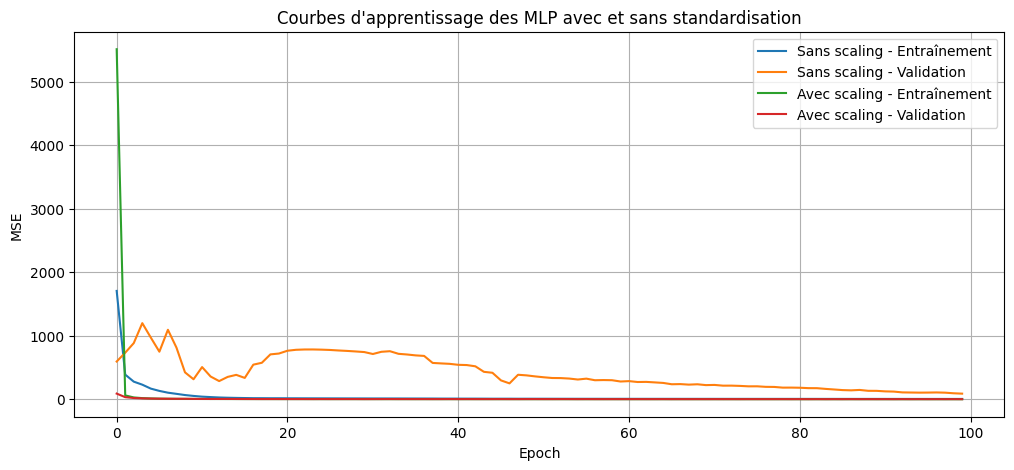

In [11]:
# ============================================================
# COURBES D'APPRENTISSAGE DES DEUX MLP
# AVEC ET SANS STANDARDISATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# MLP sans standardisation
plt.plot(
    history_mlp_sans_scaling.history["loss"],
    label="Sans scaling - Entraînement"
)

plt.plot(
    history_mlp_sans_scaling.history["val_loss"],
    label="Sans scaling - Validation"
)

# MLP avec standardisation
plt.plot(
    history_mlp_avec_scaling.history["loss"],
    label="Avec scaling - Entraînement"
)

plt.plot(
    history_mlp_avec_scaling.history["val_loss"],
    label="Avec scaling - Validation"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Courbes d'apprentissage des MLP avec et sans standardisation")
plt.legend()
plt.grid(True)

plt.show()


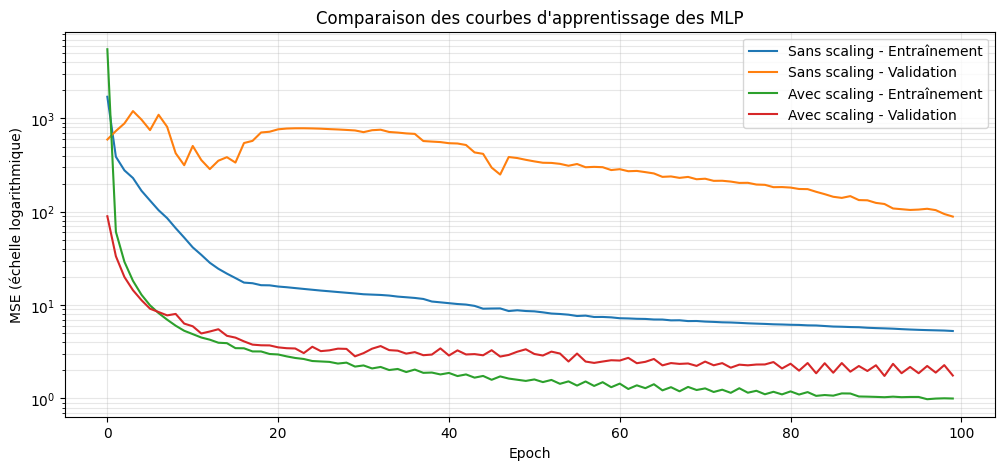

In [12]:

# ============================================================
# COURBES D'APPRENTISSAGE DES DEUX MLP
# ÉCHELLE LOGARITHMIQUE
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# MLP sans standardisation
plt.plot(
    history_mlp_sans_scaling.history["loss"],
    label="Sans scaling - Entraînement"
)

plt.plot(
    history_mlp_sans_scaling.history["val_loss"],
    label="Sans scaling - Validation"
)

# MLP avec standardisation
plt.plot(
    history_mlp_avec_scaling.history["loss"],
    label="Avec scaling - Entraînement"
)

plt.plot(
    history_mlp_avec_scaling.history["val_loss"],
    label="Avec scaling - Validation"
)

# Échelle logarithmique
plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("MSE (échelle logarithmique)")
plt.title("Comparaison des courbes d'apprentissage des MLP")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.show()


### Interprétation des courbes d'apprentissage

Les courbes d'apprentissage, présentées en échelle linéaire puis logarithmique, mettent en évidence des différences importantes dans la convergence des deux MLP.

**MLP sans standardisation**

La fonction de coût diminue progressivement sur le jeu d'entraînement, ce qui montre que le réseau parvient à apprendre malgré les différences d'échelle entre les variables explicatives.

Toutefois, la perte de validation reste élevée et présente des fluctuations importantes, particulièrement durant les premières epochs. L'écart persistant entre les pertes d'entraînement et de validation suggère des difficultés de généralisation dans cette configuration.

**MLP avec standardisation**

Les pertes d'entraînement et de validation diminuent rapidement dès les premières epochs et atteignent des valeurs nettement inférieures à celles du MLP sans standardisation.

La convergence est plus rapide et la perte de validation présente une évolution globalement plus stable. Un écart subsiste entre les deux courbes, mais les performances obtenues sur le jeu de test confirment la bonne capacité de généralisation du modèle.

**Comparaison des deux modèles**

L'échelle logarithmique permet de mieux visualiser les écarts entre les quatre courbes, qui étaient partiellement masqués sur le graphique initial par les valeurs élevées des premières epochs.

Dans les conditions de cette expérimentation, la standardisation facilite l'optimisation du réseau de neurones, accélère sa convergence et améliore significativement ses performances.

Ces observations sont cohérentes avec les métriques calculées sur le jeu de test, notamment la réduction de la RMSE de **9,3855 g/km à 1,3355 g/km**.

## 7. Tableau comparatif des performances avec et sans standardisation

Cette section présente une synthèse des performances obtenues avec et sans standardisation pour les quatre modèles étudiés : régression linéaire, Ridge, Lasso et MLP.

Pour la **régression linéaire, Ridge et Lasso**, les résultats sans standardisation proviennent du notebook de modélisation principal, tandis que les résultats avec standardisation ont été calculés dans le présent notebook.

Pour le **MLP**, les deux configurations ont été entraînées dans le cadre d'une comparaison contrôlée, en conservant la même architecture, les mêmes poids initiaux, les mêmes jeux de données et les mêmes paramètres d'entraînement. Seule la standardisation des variables explicatives diffère.

Les performances sont évaluées à l'aide de quatre métriques :

- **MAE** : erreur absolue moyenne, exprimée en g/km.
- **RMSE** : racine de l'erreur quadratique moyenne, exprimée en g/km.
- **R²** : proportion de la variance expliquée par le modèle.
- **MAPE** : erreur absolue moyenne en pourcentage, exprimée ici sous forme décimale.

Ce tableau permet d'identifier les familles de modèles pour lesquelles la standardisation apporte une amélioration des performances prédictives.

In [26]:
# ============================================================
# TABLEAU COMPARATIF - SANS / AVEC STANDARDISATION
# ============================================================

# Régression linéaire, Ridge et Lasso :
# - Sans scaling : résultats du notebook principal
# - Avec scaling : résultats calculés dans ce notebook
#
# MLP :
# - Sans et avec scaling : comparaison contrôlée réalisée
#   dans ce notebook sur le même jeu de test.

comparaison_scaling = pd.DataFrame({
    "Modèle": [
        "Régression linéaire",
        "Régression linéaire",
        "Ridge optimisé",
        "Ridge optimisé",
        "Lasso optimisé",
        "Lasso optimisé",
        "MLP",
        "MLP"
    ],

    "Scaling": [
        "Sans",
        "Avec",
        "Sans",
        "Avec",
        "Sans",
        "Avec",
        "Sans",
        "Avec"
    ],

    "MAE": [
        1.0922,
        mae_linear_scaled,
        1.0925,
        mae_best_ridge_scaled,
        1.0922,
        mae_best_lasso_scaled,
        resultats_mlp.loc["MLP sans standardisation", "MAE"],
        resultats_mlp.loc["MLP avec standardisation", "MAE"]
    ],

    "RMSE": [
        1.7402,
        rmse_linear_scaled,
        1.7401,
        rmse_best_ridge_scaled,
        1.7401,
        rmse_best_lasso_scaled,
        resultats_mlp.loc["MLP sans standardisation", "RMSE"],
        resultats_mlp.loc["MLP avec standardisation", "RMSE"]
    ],

    "R²": [
        0.9974,
        r2_linear_scaled,
        0.9974,
        r2_best_ridge_scaled,
        0.9974,
        r2_best_lasso_scaled,
        resultats_mlp.loc["MLP sans standardisation", "R²"],
        resultats_mlp.loc["MLP avec standardisation", "R²"]
    ],

    "MAPE": [
        0.0059,
        mape_linear_scaled,
        0.0060,
        mape_best_ridge_scaled,
        0.0059,
        mape_best_lasso_scaled,
        resultats_mlp.loc["MLP sans standardisation", "MAPE"],
        resultats_mlp.loc["MLP avec standardisation", "MAPE"]
    ]
})

# Affichage du tableau comparatif
display(comparaison_scaling.round(4))


,Modèle,Scaling,MAE,RMSE,R²,MAPE
0,Régression linéaire,Sans,1.0922,1.7402,0.9974,0.0059
1,Régression linéaire,Avec,1.0922,1.7402,0.9974,0.0059
2,Ridge optimisé,Sans,1.0925,1.7401,0.9974,0.0060
3,Ridge optimisé,Avec,1.0925,1.7401,0.9974,0.0060
4,Lasso optimisé,Sans,1.0922,1.7401,0.9974,0.0059
5,Lasso optimisé,Avec,1.0922,1.7401,0.9974,0.0059
6,MLP,Sans,9.1259,9.3855,0.9245,0.0457
7,MLP,Avec,0.7971,1.3355,0.9985,0.0044


## 8. Conclusion de l'expérimentation

Cette expérimentation a permis d'évaluer l'impact de la standardisation sur les performances de quatre modèles de régression : la régression linéaire, Ridge, Lasso et le MLP.

Les résultats montrent que l'effet de la standardisation dépend de la famille d'algorithmes étudiée.

### Régression linéaire

La standardisation ne modifie pas les performances de la régression linéaire dans cette expérimentation. Les résultats sont identiques à quatre décimales avec et sans scaling, avec une **MAE de 1,0922 g/km**, une **RMSE de 1,7402 g/km** et un **R² de 0,9974**.

Ce résultat est cohérent avec le fonctionnement de la régression linéaire classique, dont les prédictions ne dépendent pas de l'échelle des variables lorsque le modèle est correctement ajusté.

### Ridge et Lasso

Pour les modèles régularisés, l'effet de la standardisation est principalement visible sur le choix du paramètre de régularisation.

Pour **Ridge**, le meilleur `alpha` passe de `0.0001` sans standardisation à `1` après standardisation. Malgré cette différence, les performances restent identiques à quatre décimales, avec une **MAE de 1,0925 g/km** et un **R² de 0,9974**.

Pour **Lasso**, le `GridSearchCV` sélectionne `alpha=0.0001` après standardisation, soit la même valeur que dans la modélisation principale. Les performances du modèle optimisé restent également identiques à quatre décimales, avec une **MAE de 1,0922 g/km** et un **R² de 0,9974**.

Ces résultats montrent que la standardisation permet d'appliquer les pénalisations L1 et L2 sur des variables placées sur une échelle comparable, sans apporter ici de gain prédictif notable après optimisation.

### MLP

L'amélioration la plus importante concerne le réseau de neurones MLP.

Contrairement aux modèles linéaires, une comparaison contrôlée a été réalisée entre deux MLP utilisant la même architecture, les mêmes poids initiaux, les mêmes jeux d'apprentissage, de validation et de test, ainsi que les mêmes paramètres d'entraînement.

La seule différence entre les deux modèles concerne la standardisation des variables explicatives.

Les résultats obtenus sur le jeu de test montrent une amélioration importante des performances après standardisation :

- La **MAE** diminue de **9,1259 à 0,7971 g/km**, soit une réduction d'environ **91,3 %**.
- La **RMSE** diminue de **9,3855 à 1,3355 g/km**, soit une réduction d'environ **85,8 %**.
- Le **R²** progresse de **0,9245 à 0,9985**.
- La **MAPE** diminue de **0,0457 à 0,0044**, soit de **4,57 % à 0,44 %**.

La réduction de la RMSE est particulièrement intéressante, car cette métrique accorde davantage de poids aux erreurs de prédiction importantes.

L'analyse des courbes d'apprentissage confirme également ces observations. Sans standardisation, la convergence du MLP est plus lente et la perte de validation reste relativement élevée. Avec standardisation, les pertes d'entraînement et de validation diminuent plus rapidement et atteignent des valeurs nettement inférieures.

Ces résultats montrent que la mise à l'échelle des variables facilite l'optimisation des poids du réseau et améliore significativement sa précision prédictive dans les conditions de cette expérimentation.

### Bilan général

L'impact de la standardisation dépend du type de modèle utilisé.

Pour la **régression linéaire, Ridge et Lasso optimisés**, les performances restent pratiquement inchangées après standardisation. Dans le cas des modèles régularisés, cette transformation peut néanmoins modifier les valeurs optimales des paramètres de régularisation.

En revanche, le **MLP bénéficie fortement de la standardisation**, avec une diminution importante des erreurs de prédiction, une amélioration du R² et une convergence plus rapide.

Les modèles fondés sur les arbres, notamment Random Forest, XGBoost et LightGBM, n'ont pas été réentraînés dans cette expérimentation, car leur fonctionnement est généralement peu sensible aux transformations linéaires de l'échelle des variables.

**Cette expérimentation montre ainsi que la standardisation ne doit pas être appliquée systématiquement dans l'objectif d'améliorer les performances, mais choisie en fonction des caractéristiques du modèle utilisé.**

Elle met particulièrement en évidence son intérêt pour les réseaux de neurones, dont l'apprentissage est sensible aux différences d'échelle entre les variables explicatives.

Les résultats obtenus pour le MLP pourraient être consolidés par plusieurs entraînements utilisant différentes graines aléatoires afin de vérifier leur stabilité.